<a href="https://colab.research.google.com/github/naimazanaa2006-maker/tp1-Apprentissage-automatique/blob/main/TP1_Pretraitement_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1549]:
import pandas as pd

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

In [1550]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [1551]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [1552]:
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [1553]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [1554]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [1555]:
df['Age'] = df['Age'].fillna(df['Age'].median())

In [1556]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [1557]:
df['Fare'] = df['Fare'].fillna(df['Fare'].median())

In [1558]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [1559]:
missing_percent = (df.isnull().sum() / len(df)) * 100

print(missing_percent)

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age             0.000000
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.000000
dtype: float64


In [1560]:
df = df.drop(columns=['Cabin'])

In [1561]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [1562]:
print("Total des valeurs manquantes :", df.isnull().sum().sum())

Total des valeurs manquantes : 0


In [1563]:
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns

print(numeric_columns)

Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')


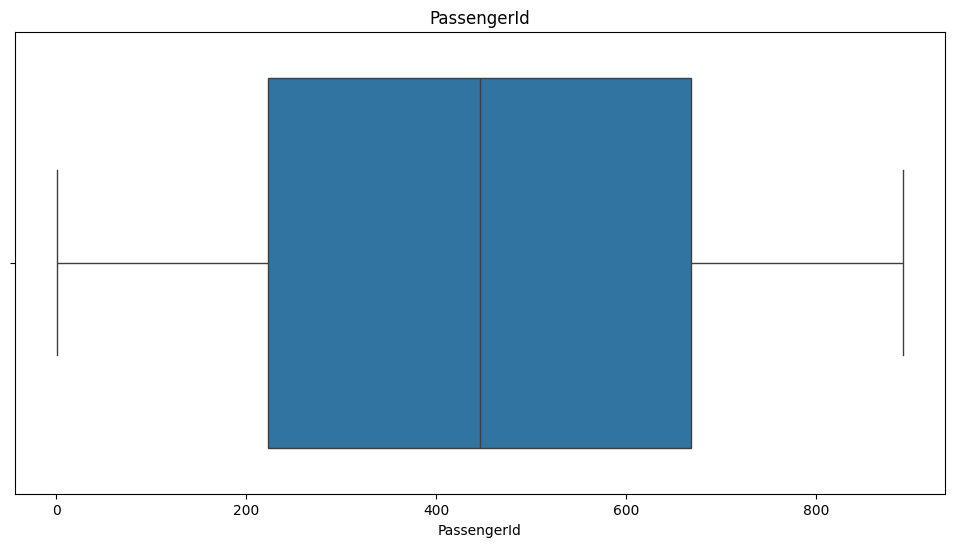

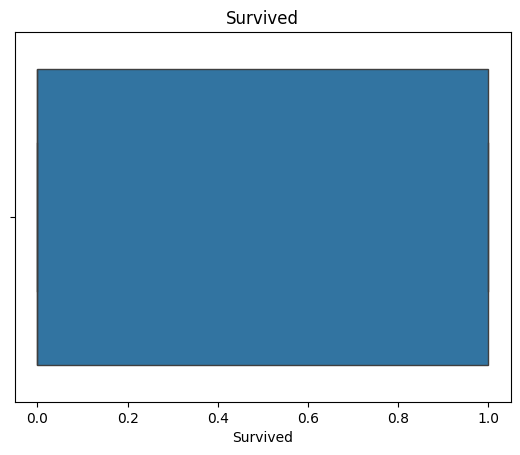

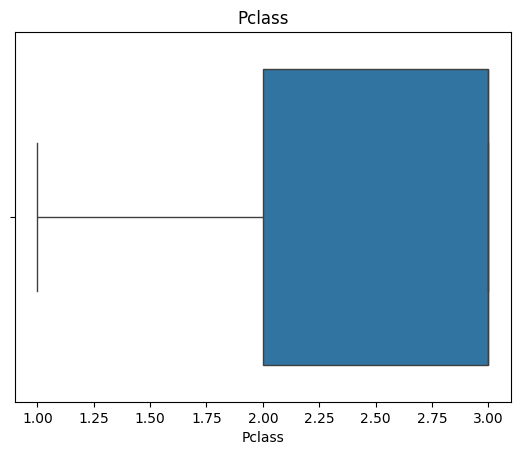

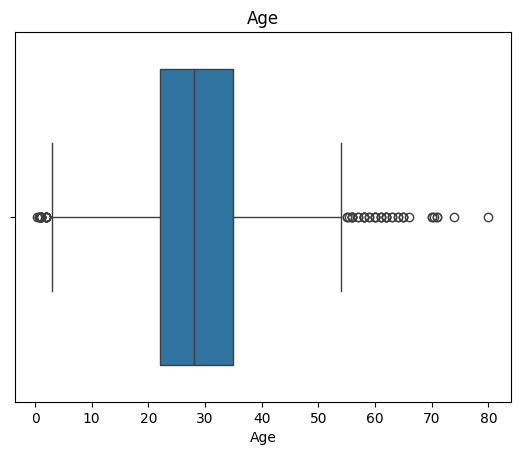

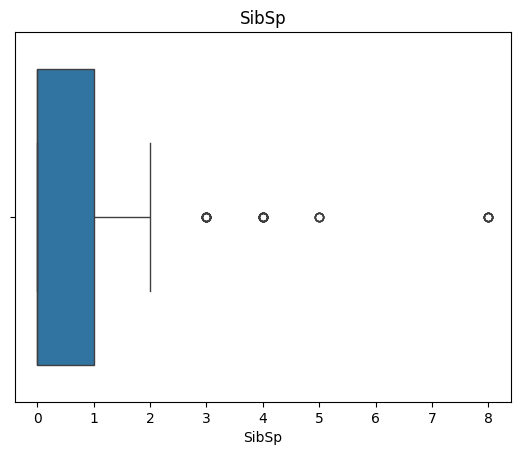

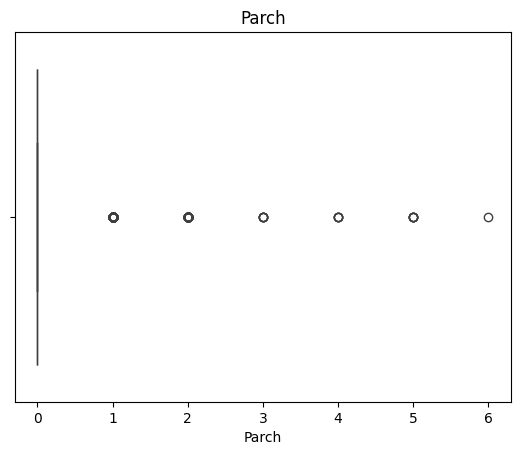

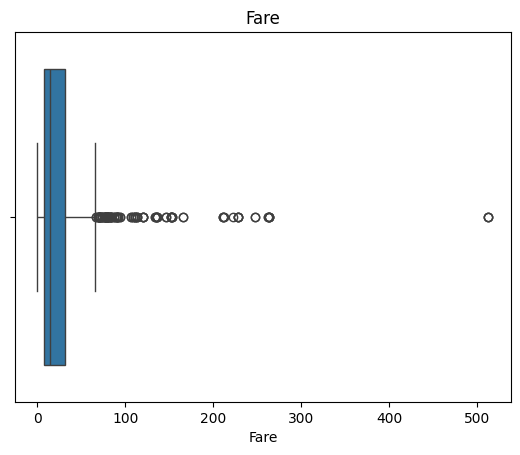

In [1564]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

for col in numeric_columns:
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

In [1565]:
Q1 = df['Age'].quantile(0.25)
Q3 = df['Age'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

median_age = df['Age'].median()

df.loc[
    (df['Age'] < lower_bound) | (df['Age'] > upper_bound),
    'Age'
] = median_age

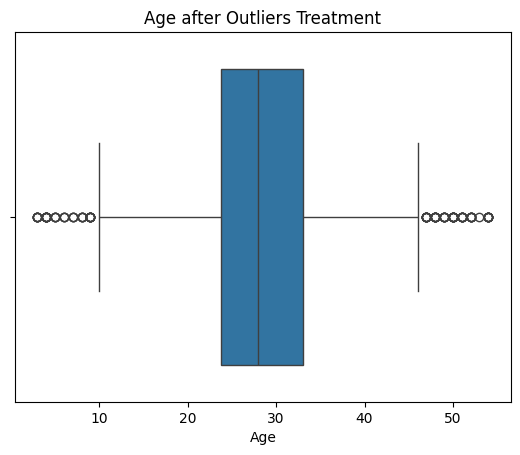

In [1566]:
sns.boxplot(x=df['Age'])
plt.title('Age after Outliers Treatment')
plt.show()

In [1567]:
Q1 = df['Fare'].quantile(0.25)
Q3 = df['Fare'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

median_fare = df['Fare'].median()

df.loc[
    (df['Fare'] < lower_bound) | (df['Fare'] > upper_bound),
    'Fare'
] = median_fare

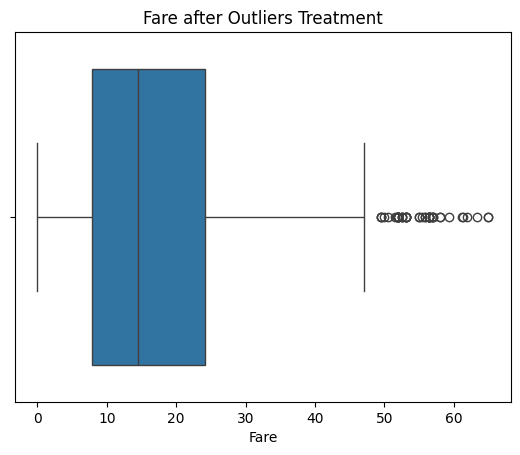

In [1568]:
sns.boxplot(x=df['Fare'])
plt.title('Fare after Outliers Treatment')
plt.show()

In [1569]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Embarked     891 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 76.7+ KB


In [1570]:
print("Valeurs manquantes :")
print(df.isnull().sum())

Valeurs manquantes :
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [1571]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,14.4542,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [1572]:
categorical_columns = df.select_dtypes(include=['object']).columns

print(categorical_columns)

Index(['Name', 'Sex', 'Ticket', 'Embarked'], dtype='object')


In [1573]:
df = pd.get_dummies(df, columns=['Sex'], dtype=int)

In [1574]:
df = pd.get_dummies(df, columns=['Embarked'], dtype=int)

In [1575]:
df.head()

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,0,1,0,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,14.4542,1,0,1,0,0
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,1,0,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,1,0,0,0,1
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,0,1,0,0,1


In [1576]:
df['Pclass'].value_counts()

,count
Pclass,
3,491
1,216
2,184


In [1577]:
print(df.dtypes)

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Sex_female       int64
Sex_male         int64
Embarked_C       int64
Embarked_Q       int64
Embarked_S       int64
dtype: object


In [1578]:
from sklearn.preprocessing import MinMaxScaler

In [1579]:
scaler = MinMaxScaler()

df[['Age_MinMax', 'Fare_MinMax']] = scaler.fit_transform(
    df[['Age', 'Fare']]
)

In [1580]:
df[['Age', 'Age_MinMax', 'Fare', 'Fare_MinMax']].head()

,Age,Age_MinMax,Fare,Fare_MinMax
0,22.0,0.372549,7.2500,0.111538
1,38.0,0.686275,14.4542,0.222372
2,26.0,0.450980,7.9250,0.121923
3,35.0,0.627451,53.1000,0.816923
4,35.0,0.627451,8.0500,0.123846


In [1581]:
from sklearn.preprocessing import StandardScaler

In [1582]:
scaler = StandardScaler()

df[['Age_Standard', 'Fare_Standard']] = scaler.fit_transform(
    df[['Age', 'Fare']]
)

In [1583]:
scaler = StandardScaler()

df[['Age_Standard', 'Fare_Standard']] = scaler.fit_transform(
    df[['Age', 'Fare']]
)

In [1584]:
df[['Age', 'Age_Standard', 'Fare', 'Fare_Standard']].head()

,Age,Age_Standard,Fare,Fare_Standard
0,22.0,-0.661724,7.2500,-0.797554
1,38.0,0.972921,14.4542,-0.230556
2,26.0,-0.253063,7.9250,-0.744429
3,35.0,0.666425,53.1000,2.811012
4,35.0,0.666425,8.0500,-0.734591


In [1585]:
print("Moyenne :")
print(df[['Age_Standard', 'Fare_Standard']].mean())

print("Ecart-type :")
print(df[['Age_Standard', 'Fare_Standard']].std())

Moyenne :
Age_Standard    -1.913920e-16
Fare_Standard   -9.569599e-17
dtype: float64
Ecart-type :
Age_Standard     1.000562
Fare_Standard    1.000562
dtype: float64


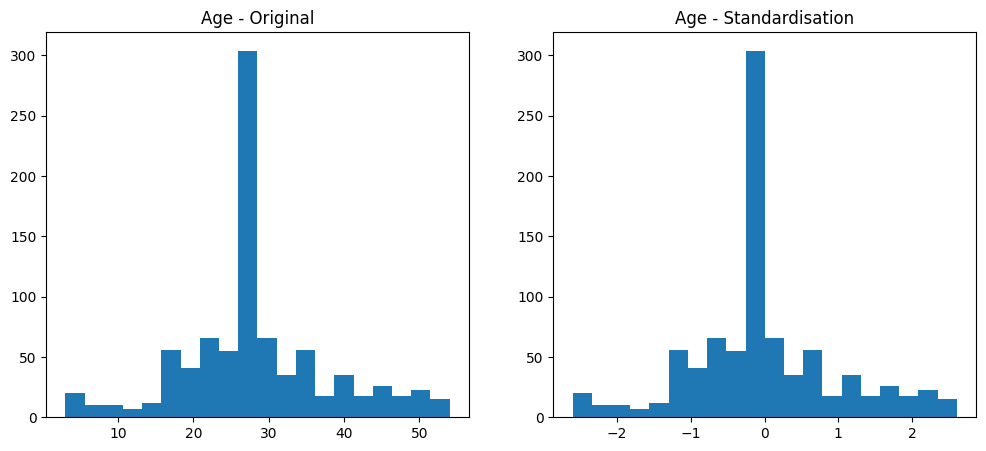

In [1586]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df['Age'], bins=20)
plt.title('Age - Original')

plt.subplot(1, 2, 2)
plt.hist(df['Age_Standard'], bins=20)
plt.title('Age - Standardisation')

plt.show()

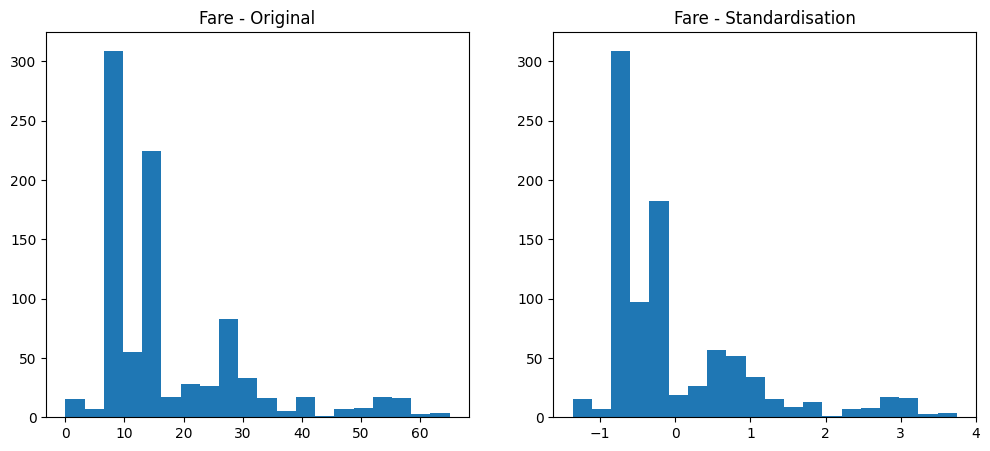

In [1587]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df['Fare'], bins=20)
plt.title('Fare - Original')

plt.subplot(1, 2, 2)
plt.hist(df['Fare_Standard'], bins=20)
plt.title('Fare - Standardisation')

plt.show()

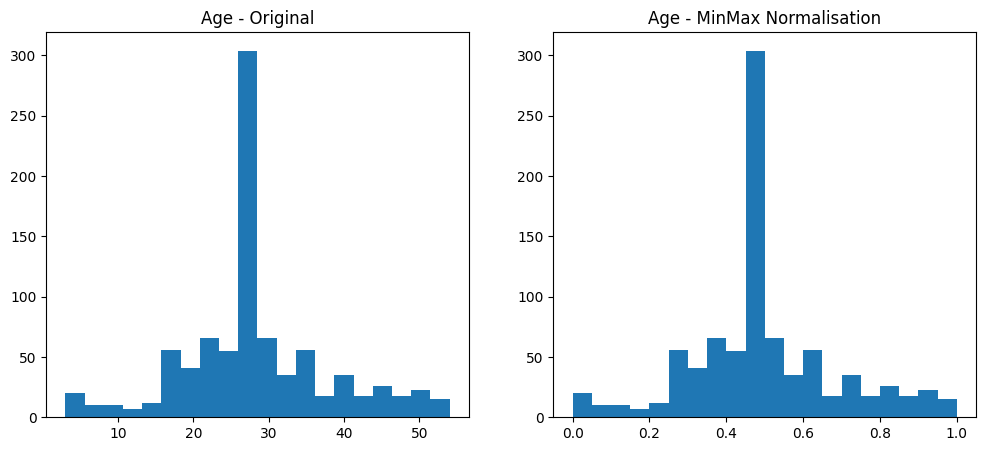

In [1588]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df['Age'], bins=20)
plt.title('Age - Original')

plt.subplot(1, 2, 2)
plt.hist(df['Age_MinMax'], bins=20)
plt.title('Age - MinMax Normalisation')

plt.show()

In [1589]:
df['Survived'].value_counts()

,count
Survived,
0,549
1,342


In [1590]:
df['Survived'].value_counts(normalize=True) * 100

,proportion
Survived,
0,61.616162
1,38.383838


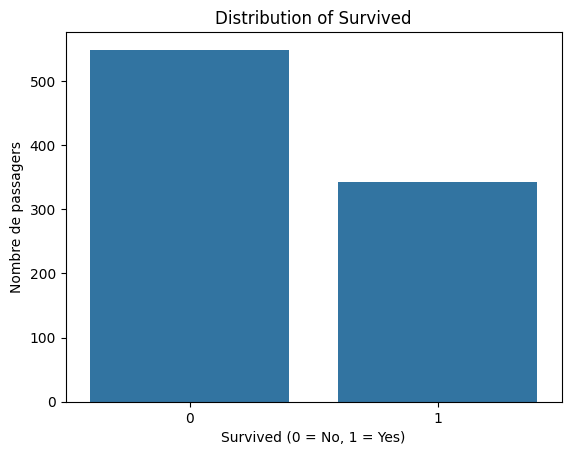

In [1591]:
sns.countplot(x='Survived', data=df)

plt.title('Distribution of Survived')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Nombre de passagers')

plt.show()

In [1592]:
from sklearn.utils import resample

In [1593]:
df_majority = df[df['Survived'] == 0]
df_minority = df[df['Survived'] == 1]

df_majority_downsampled = resample(
    df_majority,
    replace=False,
    n_samples=len(df_minority),
    random_state=42
)

df_undersampled = pd.concat([
    df_majority_downsampled,
    df_minority
])

In [1594]:
print(df_undersampled['Survived'].value_counts())

Survived
0    342
1    342
Name: count, dtype: int64


In [1595]:
!pip install imbalanced-learn

In [1596]:
from imblearn.over_sampling import SMOTE

In [1597]:
X = df.select_dtypes(include=['number']).drop(columns=['Survived'])
y = df['Survived']

In [1598]:
smote = SMOTE(random_state=42)

X_resampled, y_resampled = smote.fit_resample(X, y)

In [1599]:
print("Before SMOTE:")
print(y.value_counts())

print("\nAfter SMOTE:")
print(y_resampled.value_counts())

Before SMOTE:
Survived
0    549
1    342
Name: count, dtype: int64

After SMOTE:
Survived
0    549
1    549
Name: count, dtype: int64
